# IBM Telco Customer Churn

In [1]:
# Importing Liabraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Importing Raw Data

In [2]:
df = pd.read_csv(r"C:\Users\HiteshBajaj\All Data\DS\Projects\customer-churn-prediction\WA_Fn-UseC_-Telco-Customer-Churn.csv")

# EDA

### EDA (Exploratory Data Analysis)

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df['customerID'].nunique()

7043

In [7]:
df['TotalCharges'].unique()[:20]

array(['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5',
       '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8',
       '5681.1', '5036.3', '2686.05', '7895.15', '1022.95', '7382.25',
       '528.35', '1862.9'], dtype=object)

In [8]:
df['TotalCharges'].value_counts().head(20)

TotalCharges
         11
20.2     11
19.75     9
20.05     8
19.9      8
19.65     8
45.3      7
19.55     7
20.15     6
20.25     6
19.45     6
20.3      5
20.45     5
19.85     4
69.9      4
20.4      4
70.6      4
19.2      4
69.65     4
44        4
Name: count, dtype: int64

In [9]:
df['customerID'].nunique()

7043

In [10]:
df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [11]:
df['Churn'].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [12]:
df['TotalCharges'].unique()[:20]

array(['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5',
       '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8',
       '5681.1', '5036.3', '2686.05', '7895.15', '1022.95', '7382.25',
       '528.35', '1862.9'], dtype=object)

In [13]:
(df == ' ').sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [14]:
(df == '').sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [15]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [16]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [17]:
df[df['TotalCharges'] == ' ']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [18]:
df[df['TotalCharges'] == ' '][
    ['customerID', 'tenure', 'MonthlyCharges', 'Contract', 'Churn']
]

,customerID,tenure,MonthlyCharges,Contract,Churn
488,4472-LVYGI,0,52.55,Two year,No
753,3115-CZMZD,0,20.25,Two year,No
936,5709-LVOEQ,0,80.85,Two year,No
1082,4367-NUYAO,0,25.75,Two year,No
1340,1371-DWPAZ,0,56.05,Two year,No
3331,7644-OMVMY,0,19.85,Two year,No
3826,3213-VVOLG,0,25.35,Two year,No
4380,2520-SGTTA,0,20.00,Two year,No
5218,2923-ARZLG,0,19.70,One year,No
6670,4075-WKNIU,0,73.35,Two year,No


In [19]:
df[df['Churn'] == 'Yes']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
13,0280-XJGEX,Male,0,No,No,49,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7021,1699-HPSBG,Male,0,No,No,12,Yes,No,DSL,No,...,No,Yes,Yes,No,One year,Yes,Electronic check,59.80,727.8,Yes
7026,8775-CEBBJ,Female,0,No,No,9,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),44.20,403.35,Yes
7032,6894-LFHLY,Male,1,No,No,1,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,75.75,75.75,Yes
7034,0639-TSIQW,Female,0,No,No,67,Yes,Yes,Fiber optic,Yes,...,Yes,No,Yes,No,Month-to-month,Yes,Credit card (automatic),102.95,6886.25,Yes


### Creating Tenure Groups

In [20]:
import pandas as pd

df['tenure_group'] = pd.cut(
    df['tenure'],
    bins=[0, 12, 24, 48, 72],
    labels=['0–12 months', '13–24 months', '25–48 months', '49–72 months'],
    include_lowest=True
)


In [21]:
df.groupby('tenure_group')['Churn'].value_counts()


C:\Users\HiteshBajaj\AppData\Local\Temp\ipykernel_18852\3781232415.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('tenure_group')['Churn'].value_counts()


tenure_group  Churn
0–12 months   No       1149
              Yes      1037
13–24 months  No        730
              Yes       294
25–48 months  No       1269
              Yes       325
49–72 months  No       2026
              Yes       213
Name: count, dtype: int64

In [22]:
df[['tenure', 'tenure_group']].head()


,tenure,tenure_group
0,1,0–12 months
1,34,25–48 months
2,2,0–12 months
3,45,25–48 months
4,2,0–12 months


### Churn percentage for each tenure group

In [23]:
churn_rate = df.groupby('tenure_group', observed=True)['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

churn_rate


tenure_group
0–12 months     47.438243
13–24 months    28.710938
25–48 months    20.388959
49–72 months     9.513176
Name: Churn, dtype: float64

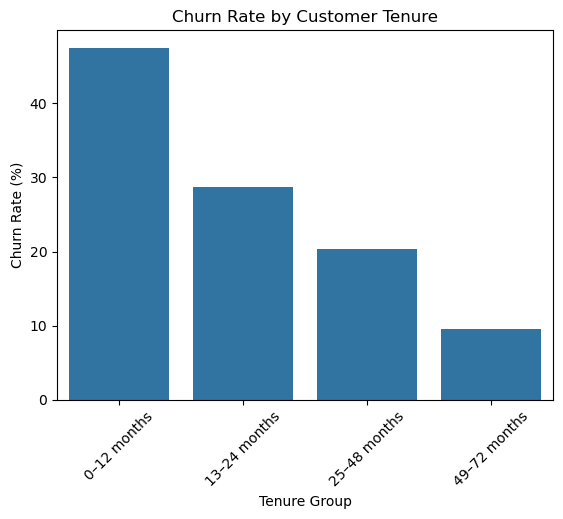

In [24]:
# Churn percentage Bar plot

sns.barplot(
    x=churn_rate.index,
    y=churn_rate.values
)
plt.xlabel('Tenure Group')
plt.ylabel('Churn Rate (%)')
plt.title('Churn Rate by Customer Tenure')
plt.xticks(rotation=45)
plt.show()

### Tenure Analysis

In [25]:
tenure_analysis = df.groupby('tenure_group', observed=True).agg(
    customers=('customerID', 'count'),
    churned=('Churn', lambda x: (x == 'Yes').sum()),
    churn_rate=('Churn', lambda x: (x == 'Yes').mean() * 100)
)

tenure_analysis['churn_rate'] = tenure_analysis['churn_rate'].round(2)

tenure_analysis


,customers,churned,churn_rate
tenure_group,,,
0–12 months,2186,1037,47.44
13–24 months,1024,294,28.71
25–48 months,1594,325,20.39
49–72 months,2239,213,9.51


### Contract Analysis

In [26]:
contract_analysis = df.groupby('Contract').agg(
    Customers=('customerID', 'count'),
    Churned=('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate = ('Churn', lambda x: (x == 'Yes').mean() * 100)
)
contract_analysis['Churn_rate'] = contract_analysis['Churn_rate'].round(2)

contract_analysis

,Customers,Churned,Churn_rate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83


### Monthly Charges Vs Churn

In [27]:
df[['MonthlyCharges', 'Churn']].head()

,MonthlyCharges,Churn
0,29.85,No
1,56.95,No
2,53.85,Yes
3,42.30,No
4,70.70,Yes


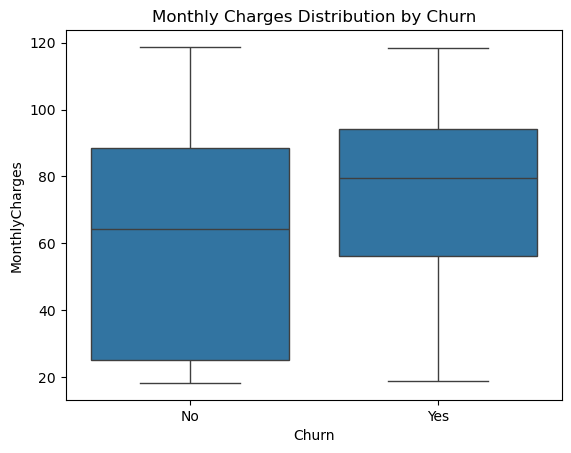

In [28]:
sns.boxplot(
    x='Churn',
    y='MonthlyCharges',
    data=df
)

plt.xlabel('Churn')
plt.ylabel('MonthlyCharges')
plt.title('Monthly Charges Distribution by Churn')
plt.show()

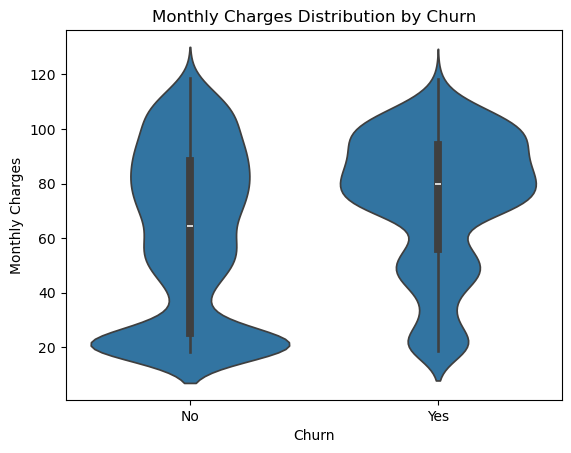

In [29]:
sns.violinplot(
    x='Churn',
    y='MonthlyCharges',
    data=df
)

plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.title('Monthly Charges Distribution by Churn')
plt.show()


In [30]:
df.groupby('Churn')['MonthlyCharges'].agg(
    ['count', 'mean', 'median', 'min', 'max']
).round(2)


,count,mean,median,min,max
Churn,,,,,
No,5174,61.27,64.43,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


In [31]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0–12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.5,No,25–48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0–12 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25–48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0–12 months


### Churn rate by Internet Service Type

In [32]:
Internet_Service = df.groupby('InternetService').agg(
    Customers=('InternetService', 'count'),
    Churned=('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate = ('Churn', lambda x: (x == 'Yes').mean() * 100)
)
Internet_Service['Churn_rate'] = Internet_Service['Churn_rate'].round(2)

Internet_Service

,Customers,Churned,Churn_rate
InternetService,,,
DSL,2421,459,18.96
Fiber optic,3096,1297,41.89
No,1526,113,7.40


### Churn rate by Payment Method

In [33]:
Payment_Method = df.groupby('PaymentMethod').agg(
    Customers=('PaymentMethod', 'count'),
    Churned=('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate = ('Churn', lambda x: (x == 'Yes').mean() * 100)
)
Payment_Method['Churn_rate'] = Payment_Method['Churn_rate'].round(2)

Payment_Method

,Customers,Churned,Churn_rate
PaymentMethod,,,
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11


### Churn rate by Senior Citizen

In [34]:
Senior_citizen = df.groupby('SeniorCitizen').agg(
    Customers=('SeniorCitizen', 'count'),
    Churned = ('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate = ('Churn', lambda x: (x == 'Yes').mean() * 100)
)
Senior_citizen['Churn_rate'] = Senior_citizen['Churn_rate'].round(2)
Senior_citizen

,Customers,Churned,Churn_rate
SeniorCitizen,,,
0,5901,1393,23.61
1,1142,476,41.68


### Churn rate by Tech_Support

In [35]:
Tech_support = df.groupby('TechSupport').agg(
    Customers=('TechSupport', 'count'),
    Churned = ('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate = ('Churn', lambda x: (x == 'Yes').mean() * 100)
)
Tech_support['Churn_rate'] = Tech_support['Churn_rate'].round(2)
Tech_support

,Customers,Churned,Churn_rate
TechSupport,,,
No,3473,1446,41.64
No internet service,1526,113,7.40
Yes,2044,310,15.17


### Churn rate by Online_security

In [36]:
Online_security = df.groupby('OnlineSecurity').agg(
    Customers=('OnlineSecurity', 'count'),
    Churned = ('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate = ('Churn', lambda x: (x == 'Yes').mean()*100)
)
Online_security['Churn_rate'] = Online_security['Churn_rate'].round(2)
Online_security

,Customers,Churned,Churn_rate
OnlineSecurity,,,
No,3498,1461,41.77
No internet service,1526,113,7.40
Yes,2019,295,14.61


In [37]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,tenure_group
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0–12 months
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,No,One year,No,Mailed check,56.95,1889.5,No,25–48 months
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0–12 months
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25–48 months
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0–12 months


### Churn rate by Partners

In [38]:
Partners = df.groupby('Partner').agg(
    Customers=('Partner', 'count'),
    Churned = ('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate = ('Churn', lambda x: (x == 'Yes').mean()*100)
)
Partners['Churn_rate'] = Partners['Churn_rate'].round(2)
Partners

,Customers,Churned,Churn_rate
Partner,,,
No,3641,1200,32.96
Yes,3402,669,19.66


### Churn rate by Dependent

In [39]:
Dependent = df.groupby('Dependents').agg(
    Customers=('Dependents', 'count'),
    Churned = ('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate = ('Churn', lambda x: (x == 'Yes').mean()*100)
)
Dependent['Churn_rate'] = Dependent['Churn_rate'].round(2)
Dependent

,Customers,Churned,Churn_rate
Dependents,,,
No,4933,1543,31.28
Yes,2110,326,15.45


### Churn by both Contract and TenureGroup

In [40]:
# Create tenure groups
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[0, 12, 24, 48, 72],
    labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months']
)

Contract_tenure = df.groupby(
    ['Contract', 'TenureGroup'],
    observed=True
).agg(
    Customers=('Churn', 'count'),
    Churned=('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate=('Churn', lambda x: (x == 'Yes').mean() * 100)
).reset_index()

Contract_tenure['Churn_rate'] = Contract_tenure['Churn_rate'].round(2)

Contract_tenure

,Contract,TenureGroup,Customers,Churned,Churn_rate
0,Month-to-month,0-12 months,1994,1024,51.35
1,Month-to-month,13-24 months,737,278,37.72
2,Month-to-month,25-48 months,802,264,32.92
3,Month-to-month,49-72 months,342,89,26.02
4,One year,0-12 months,123,13,10.57
5,One year,13-24 months,197,16,8.12
6,One year,25-48 months,518,55,10.62
7,One year,49-72 months,634,82,12.93
8,Two year,0-12 months,58,0,0.00
9,Two year,13-24 months,90,0,0.00


### Churn by both Contract and InternetService

In [41]:
Contract_internet = df.groupby(
    ['Contract', 'InternetService']
).agg(
    Customers=('Churn', 'count'),
    Churned=('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate=('Churn', lambda x: (x == 'Yes').mean() * 100)
).reset_index()

Contract_internet['Churn_rate'] = Contract_internet['Churn_rate'].round(2)

Contract_internet

,Contract,InternetService,Customers,Churned,Churn_rate
0,Month-to-month,DSL,1223,394,32.22
1,Month-to-month,Fiber optic,2128,1162,54.61
2,Month-to-month,No,524,99,18.89
3,One year,DSL,570,53,9.30
4,One year,Fiber optic,539,104,19.29
5,One year,No,364,9,2.47
6,Two year,DSL,628,12,1.91
7,Two year,Fiber optic,429,31,7.23
8,Two year,No,638,5,0.78


### Churn by both Contract and TechSupport

In [42]:
Contract_techsupport = df.groupby(
    ['Contract', 'TechSupport']
).agg(
    Customers=('Churn', 'count'),
    Churned=('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate=('Churn', lambda x: (x == 'Yes').mean() * 100)
).reset_index()

Contract_techsupport['Churn_rate'] = (
    Contract_techsupport['Churn_rate'].round(2)
)

Contract_techsupport

,Contract,TechSupport,Customers,Churned,Churn_rate
0,Month-to-month,No,2680,1350,50.37
1,Month-to-month,No internet service,524,99,18.89
2,Month-to-month,Yes,671,206,30.70
3,One year,No,557,82,14.72
4,One year,No internet service,364,9,2.47
5,One year,Yes,552,75,13.59
6,Two year,No,236,14,5.93
7,Two year,No internet service,638,5,0.78
8,Two year,Yes,821,29,3.53


In [43]:
# Create tenure groups
df['TenureGroup'] = pd.cut(
    df['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-12 months', '13-24 months', '25-48 months', '49-72 months']
)

Contract_tenure = df.groupby(
    ['Contract', 'TenureGroup'],
    observed=True
).agg(
    Customers=('Churn', 'count'),
    Churned=('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate=('Churn', lambda x: (x == 'Yes').mean() * 100)
).reset_index()

Contract_tenure['Churn_rate'] = Contract_tenure['Churn_rate'].round(2)

Contract_tenure

,Contract,TenureGroup,Customers,Churned,Churn_rate
0,Month-to-month,0-12 months,1994,1024,51.35
1,Month-to-month,13-24 months,737,278,37.72
2,Month-to-month,25-48 months,802,264,32.92
3,Month-to-month,49-72 months,342,89,26.02
4,One year,0-12 months,124,13,10.48
5,One year,13-24 months,197,16,8.12
6,One year,25-48 months,518,55,10.62
7,One year,49-72 months,634,82,12.93
8,Two year,0-12 months,68,0,0.00
9,Two year,13-24 months,90,0,0.00


### Contract × InternetService × TenureGroup

In [44]:
# Contract × InternetService × TenureGroup

segment_analysis = df.groupby(
    ['Contract', 'InternetService', 'TenureGroup'],
    observed=True
).agg(
    Customers=('Churn', 'count'),
    Churned=('Churn', lambda x: (x == 'Yes').sum()),
    Churn_rate=('Churn', lambda x: (x == 'Yes').mean() * 100)
).reset_index()

segment_analysis['Churn_rate'] = (
    segment_analysis['Churn_rate'].round(2)
)

segment_analysis

,Contract,InternetService,TenureGroup,Customers,Churned,Churn_rate
0,Month-to-month,DSL,0-12 months,690,293,42.46
1,Month-to-month,DSL,13-24 months,232,55,23.71
2,Month-to-month,DSL,25-48 months,227,36,15.86
3,Month-to-month,DSL,49-72 months,74,10,13.51
4,Month-to-month,Fiber optic,0-12 months,916,643,70.20
5,Month-to-month,Fiber optic,13-24 months,425,215,50.59
6,Month-to-month,Fiber optic,25-48 months,521,226,43.38
7,Month-to-month,Fiber optic,49-72 months,266,78,29.32
8,Month-to-month,No,0-12 months,388,88,22.68
9,Month-to-month,No,13-24 months,80,8,10.00


### Top 10 Segments churn rate

In [45]:
top_10_segments = segment_analysis.sort_values(
    'Churn_rate',
    ascending=False
).head(10)

top_10_segments

,Contract,InternetService,TenureGroup,Customers,Churned,Churn_rate
4,Month-to-month,Fiber optic,0-12 months,916,643,70.20
5,Month-to-month,Fiber optic,13-24 months,425,215,50.59
11,Month-to-month,No,49-72 months,2,1,50.00
6,Month-to-month,Fiber optic,25-48 months,521,226,43.38
0,Month-to-month,DSL,0-12 months,690,293,42.46
7,Month-to-month,Fiber optic,49-72 months,266,78,29.32
16,One year,Fiber optic,0-12 months,7,2,28.57
1,Month-to-month,DSL,13-24 months,232,55,23.71
8,Month-to-month,No,0-12 months,388,88,22.68
18,One year,Fiber optic,25-48 months,154,31,20.13


In [46]:
top_10_segments = (
    segment_analysis[
        segment_analysis['Customers'] >= 100
    ]
    .sort_values(
        ['Churn_rate', 'Customers'],
        ascending=[False, False]
    )
    .head(10)
)

top_10_segments

,Contract,InternetService,TenureGroup,Customers,Churned,Churn_rate
4,Month-to-month,Fiber optic,0-12 months,916,643,70.20
5,Month-to-month,Fiber optic,13-24 months,425,215,50.59
6,Month-to-month,Fiber optic,25-48 months,521,226,43.38
0,Month-to-month,DSL,0-12 months,690,293,42.46
7,Month-to-month,Fiber optic,49-72 months,266,78,29.32
1,Month-to-month,DSL,13-24 months,232,55,23.71
8,Month-to-month,No,0-12 months,388,88,22.68
18,One year,Fiber optic,25-48 months,154,31,20.13
19,One year,Fiber optic,49-72 months,355,67,18.87
2,Month-to-month,DSL,25-48 months,227,36,15.86


### High_Risk Customers

In [47]:
high_risk = df[
    (df['Contract'] == 'Month-to-month') &
    (df['InternetService'] == 'Fiber optic') &
    (df['TenureGroup'] == '0-12 months')
]

In [48]:
high_risk.shape

(916, 23)

### High Risk customers by PaymentMethod

In [49]:
high_risk.groupby('PaymentMethod')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

PaymentMethod
Bank transfer (automatic)    81.609195
Credit card (automatic)      61.333333
Electronic check             71.156894
Mailed check                 62.601626
Name: Churn, dtype: float64

### High Risk customers by TechSupport

In [50]:
    high_risk.groupby('TechSupport')['Churn'].apply(
        lambda x: (x == 'Yes').mean() * 100
    )

TechSupport
No     71.068427
Yes    61.445783
Name: Churn, dtype: float64

### High Risk customers by OnlineSecurity

In [51]:
high_risk.groupby('OnlineSecurity')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

OnlineSecurity
No     71.875000
Yes    53.571429
Name: Churn, dtype: float64

### High Risk customers by SeniorCitizen

In [52]:
high_risk.groupby('SeniorCitizen')['Churn'].apply(
    lambda x: (x == 'Yes').mean() * 100
)

SeniorCitizen
0    69.241983
1    73.043478
Name: Churn, dtype: float64

### High Risk customers by MonthlyCharges

In [53]:
high_risk.groupby('Churn')['MonthlyCharges'].agg(
    ['count', 'mean', 'median']
).round(2)

,count,mean,median
Churn,,,
No,273,80.6,79.15
Yes,643,82.7,80.50


### Rest customers which are not High_Risk

In [54]:
rest = df.loc[~df.index.isin(high_risk.index)]

### OnlineSecurity Churn Count High Risk VS Rest

In [55]:
pd.crosstab(
    high_risk['OnlineSecurity'],
    columns='count',
    normalize=True
).mul(100).round(2)

col_0,count
OnlineSecurity,
No,90.83
Yes,9.17


In [56]:
pd.crosstab(
    rest['OnlineSecurity'],
    columns='count',
    normalize=True
).mul(100).round(2)

col_0,count
OnlineSecurity,
No,43.51
No internet service,24.91
Yes,31.58


### PaymentMethod Churn Count High Risk VS Rest

In [57]:
# PaymentMethod
pd.crosstab(
    high_risk['PaymentMethod'],
    columns='count',
    normalize=True
).mul(100).round(2)

pd.crosstab(
    rest['PaymentMethod'],
    columns='count',
    normalize=True
).mul(100).round(2)


col_0,count
PaymentMethod,
Bank transfer (automatic),23.78
Credit card (automatic),23.62
Electronic check,28.30
Mailed check,24.30


In [58]:
# PaymentMethod
pd.crosstab(
    high_risk['PaymentMethod'],
    columns='count',
    normalize=True
).mul(100).round(2)

col_0,count
PaymentMethod,
Bank transfer (automatic),9.50
Credit card (automatic),8.19
Electronic check,68.89
Mailed check,13.43


In [59]:
pd.crosstab(
    rest['PaymentMethod'],
    columns='count',
    normalize=True
).mul(100).round(2)

col_0,count
PaymentMethod,
Bank transfer (automatic),23.78
Credit card (automatic),23.62
Electronic check,28.30
Mailed check,24.30


In [60]:
print("High-risk:")
print(
    pd.crosstab(
        high_risk['PaymentMethod'],
        columns='count',
        normalize=True
    ).mul(100).round(2)
)

print("\nRest:")
print(
    pd.crosstab(
        rest['PaymentMethod'],
        columns='count',
        normalize=True
    ).mul(100).round(2)
)

High-risk:
col_0                      count
PaymentMethod                   
Bank transfer (automatic)   9.50
Credit card (automatic)     8.19
Electronic check           68.89
Mailed check               13.43

Rest:
col_0                      count
PaymentMethod                   
Bank transfer (automatic)  23.78
Credit card (automatic)    23.62
Electronic check           28.30
Mailed check               24.30


### TechSupport Churn Count High Risk VS Rest

In [61]:
print("High-risk:")
print(
    pd.crosstab(
        high_risk['TechSupport'],
        columns='count',
        normalize=True
    ).mul(100).round(2)
)

print("\nRest:")
print(
    pd.crosstab(
        rest['TechSupport'],
        columns='count',
        normalize=True
    ).mul(100).round(2)
)

High-risk:
col_0        count
TechSupport       
No           90.94
Yes           9.06

Rest:
col_0                count
TechSupport               
No                   43.09
No internet service  24.91
Yes                  32.01


### Overall Churn rate

In [62]:
overall_churn = ((df['Churn']== 'Yes').mean() * 100).round(2)
print(overall_churn)

26.54


In [63]:
df['Churn'].value_counts(normalize=True).mul(100).round(2)


Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [64]:
overall_churn = ((df['Churn'] == 'Yes').mean() * 100).round(2)

print(f"Overall churn rate: {overall_churn}%")


Overall churn rate: 26.54%


In [65]:
len(high_risk)

916

In [66]:
high_risk_churn = (high_risk['Churn'] == 'Yes').mean() * 100
round(high_risk_churn, 2)


np.float64(70.2)

# Data Cleaning

### Inspect rows with blank TotalCharges

In [67]:
blank_charges = df[
    df['TotalCharges'].astype(str).str.strip() == ''
    ]
blank_charges[
    ['tenure','MonthlyCharges', 'TotalCharges','Churn']
    ]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [68]:
blank_charges['tenure'].value_counts()

tenure
0    11
Name: count, dtype: int64

### Cleaning Blank Rows

In [69]:
import numpy as np
import pandas as pd

df['TotalCharges']= pd.to_numeric(
    df['TotalCharges'].replace(r'^\s*$', np.nan, regex=True),
    errors='coerce'
)

In [70]:
df['TotalCharges'].dtype

dtype('float64')

In [71]:
df['TotalCharges'].isna().sum()

np.int64(11)

In [72]:
df.loc[
    df['TotalCharges'].isna(),
    ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']
]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [73]:
# Dataset dimensions
print(df.shape)

# Missing values
print(
    df.isna().sum().sort_values(ascending=False).head(10)
)

# Data types
print(df.dtypes)

# Duplicate customer records
print(df['customerID'].duplicated().sum())

(7043, 23)
TotalCharges        11
customerID           0
TechSupport          0
tenure_group         0
Churn                0
MonthlyCharges       0
PaymentMethod        0
PaperlessBilling     0
Contract             0
StreamingMovies      0
dtype: int64
customerID            object
gender                object
SeniorCitizen          int64
Partner               object
Dependents            object
tenure                 int64
PhoneService          object
MultipleLines         object
InternetService       object
OnlineSecurity        object
OnlineBackup          object
DeviceProtection      object
TechSupport           object
StreamingTV           object
StreamingMovies       object
Contract              object
PaperlessBilling      object
PaymentMethod         object
MonthlyCharges       float64
TotalCharges         float64
Churn                 object
tenure_group        category
TenureGroup         category
dtype: object
0


In [74]:
df = df.drop(columns=['tenure_group'])

In [75]:
df.shape

(7043, 22)

# Machine Learning Model

### Creating Target and Predictors

In [76]:
from sklearn.model_selection import train_test_split

# Target
y = df['Churn'].map({'No':0, 'Yes':1})

# Predictors

X = df.drop(
   columns=['Churn',
    'customerID',
    'TenureGroup'
    ]
)

# Stratified Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\n Training Churn Rate : ")
print(y_train.mean().round(4))

print("\n Testing Churn Rate : ")
print(y_test.mean().round(4))



X_train: (5634, 19)
X_test: (1409, 19)

 Training Churn Rate : 
0.2654

 Testing Churn Rate : 
0.2654


### Identify numerical and categorical columns

In [77]:
numeric_features = X_train.select_dtypes(
    include =['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include = ['object', 'category']
).columns.tolist()

print("Numerical Features :", numeric_features)
print("Number of Numerical Features :", len(numeric_features))

print("\n Categorical Features:", categorical_features)
print("Number of Categorical Features:", len(categorical_features))

Numerical Features : ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Number of Numerical Features : 4

 Categorical Features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of Categorical Features: 15


### Preprocessing Pipeline

In [78]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression

# Numerical preprocessing

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy= 'median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps= [
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder',OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers= [
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Complete model pipeline

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

### Training the Model

In [79]:
model.fit(X_train, y_train)

print("Model Training Succesfull.")

Model Training Succesfull.


### Predictions

In [80]:
# Predict Churn Classes (0 or 1)
y_pred = model.predict(X_test)

# Predict Churn Possibilities
y_prob = model.predict_proba(X_test)[:,1]

print("Predictions Generated.")
print("First 10 predictions:", y_pred[:10])
print("First 10 Churn Possibilities:", y_prob[:10].round(3))

Predictions Generated.
First 10 predictions: [0 1 0 0 0 1 0 0 0 0]
First 10 Churn Possibilities: [0.045 0.684 0.059 0.402 0.022 0.604 0.449 0.13  0.003 0.395]


In [81]:
### Evaluate the Model

from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Accuracy:", round(accuracy_score(y_test,y_pred),4))
print("Precision:", round(precision_score(y_test, y_pred),4))
print("Recall:", round(recall_score(y_test, y_pred),4))
print("F1 Score:", round(f1_score(y_test, y_pred),4))
print("ROC-AUC:",round(roc_auc_score(y_test,y_prob),4))

print("\n Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['No Churn', 'Churn']
))

Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1 Score: 0.604
ROC-AUC: 0.8419

 Confusion Matrix:
[[926 109]
 [165 209]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



### Comparing Thresholds

In [82]:
from sklearn.metrics import(
precision_score,
recall_score,
f1_score,
confusion_matrix
)

thresholds = [0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)
    print(f"\n Threshold: {threshold}")

    print("Precision:",
         round(precision_score(y_test, y_pred_threshold),3))

    print("Recall:",
         round(recall_score(y_test,y_pred_threshold),3))

    print("F1 Score:",
         round(f1_score(y_test, y_pred_threshold),3))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred_threshold))


 Threshold: 0.3
Precision: 0.519
Recall: 0.754
F1 Score: 0.615
Confusion Matrix:
[[774 261]
 [ 92 282]]

 Threshold: 0.4
Precision: 0.569
Recall: 0.668
F1 Score: 0.615
Confusion Matrix:
[[846 189]
 [124 250]]

 Threshold: 0.5
Precision: 0.657
Recall: 0.559
F1 Score: 0.604
Confusion Matrix:
[[926 109]
 [165 209]]

 Threshold: 0.6
Precision: 0.718
Recall: 0.401
F1 Score: 0.515
Confusion Matrix:
[[976  59]
 [224 150]]


### Model interpretation - Need to Understand this

In [83]:
# Get the fitted preprocessing step
preprocessor_fitted = model.named_steps['preprocessor']

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Get logistic regression coefficients
coefficients = model.named_steps['classifier'].coef_[0]

# Create a dataframe
coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients
})

# Add absolute coefficient for sorting
coef_df['abs_coefficient'] = coef_df['coefficient'].abs()

# Sort by strongest relationship
coef_df = coef_df.sort_values(
    'abs_coefficient',
    ascending=False
)

coef_df.head(20)

,feature,coefficient,abs_coefficient
1,num__tenure,-1.241319,1.241319
38,cat__Contract_Two year,-0.772261,0.772261
15,cat__InternetService_DSL,-0.652406,0.652406
16,cat__InternetService_Fiber optic,0.640026,0.640026
2,num__MonthlyCharges,-0.596392,0.596392
36,cat__Contract_Month-to-month,0.579304,0.579304
3,num__TotalCharges,0.516708,0.516708
39,cat__PaperlessBilling_No,-0.343260,0.343260
22,cat__OnlineBackup_No internet service,-0.301082,0.301082
17,cat__InternetService_No,-0.301082,0.301082


In [84]:
# Strongest positive coefficients
print("Top features associated with higher churn:")
print(
    coef_df
    .sort_values('coefficient', ascending=False)
    [['feature', 'coefficient']]
    .head(10)
)

print("\nTop features associated with lower churn:")
print(
    coef_df
    .sort_values('coefficient', ascending=True)
    [['feature', 'coefficient']]
    .head(10)
)

Top features associated with higher churn:
                                feature  coefficient
16     cat__InternetService_Fiber optic     0.640026
36         cat__Contract_Month-to-month     0.579304
3                     num__TotalCharges     0.516708
35             cat__StreamingMovies_Yes     0.204014
32                 cat__StreamingTV_Yes     0.203626
43  cat__PaymentMethod_Electronic check     0.198412
18               cat__OnlineSecurity_No     0.157023
27                  cat__TechSupport_No     0.132115
14               cat__MultipleLines_Yes     0.105954
0                    num__SeniorCitizen     0.053929

Top features associated with lower churn:
                                     feature  coefficient
1                                num__tenure    -1.241319
38                    cat__Contract_Two year    -0.772261
15                  cat__InternetService_DSL    -0.652406
2                        num__MonthlyCharges    -0.596392
39                  cat__PaperlessBilling

# Experiment: treat tenure as groups

In [85]:
X_train_v2 = X_train.copy()
X_test_v2 = X_test.copy()

### create the tenure groups

In [86]:
bins = [-1, 12, 24, 48, 72]
labels = ['0-12', '13-24', '25-48', '49-72']

X_train_v2['TenureGroup'] = pd.cut(
    X_train_v2['tenure'],
    bins=bins,
    labels=labels
)

X_test_v2['TenureGroup'] = pd.cut(
    X_test_v2['tenure'],
    bins=bins,
    labels=labels
)

In [87]:
print(X_train_v2['TenureGroup'].value_counts().sort_index())

TenureGroup
0-12     1737
13-24     818
25-48    1290
49-72    1789
Name: count, dtype: int64


# Model V2

### Build Model V2 and compare it fairly with our baseline

### Identify the new feature types

In [88]:
numeric_features_v2 = X_train_v2.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features_v2 = X_train_v2.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical features:", numeric_features_v2)
print("\nCategorical features:", categorical_features_v2)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


### Build Model V2

In [89]:
numeric_transformer_v2 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer_v2 = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_v2 = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_v2, numeric_features_v2),
        ('cat', categorical_transformer_v2, categorical_features_v2)
    ]
)

model_v2 = Pipeline(steps=[
    ('preprocessor', preprocessor_v2),
    ('classifier', LogisticRegression(max_iter=1000))
])

### Training

In [90]:
model_v2.fit(X_train_v2, y_train)

print("Model V2 training completed.")

Model V2 training completed.


### Model Evalutation

In [91]:
y_pred_v2 = model_v2.predict(X_test_v2)
y_prob_v2 = model_v2.predict_proba(X_test_v2)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred_v2), 4))
print("Precision:", round(precision_score(y_test, y_pred_v2), 4))
print("Recall:", round(recall_score(y_test, y_pred_v2), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_v2), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_v2), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_v2))

Accuracy: 0.7991
Precision: 0.6532
Recall: 0.5187
F1 Score: 0.5782
ROC-AUC: 0.8422

Confusion Matrix:
[[932 103]
 [180 194]]


# Random Forest

Why Random Forest?

Our Logistic Regression essentially learns a relatively smooth relationship between the features and churn.

Random Forest works differently. It builds many decision trees and can capture nonlinear relationships and interactions.

### 1. Prepare the data

In [92]:
X_train_rf = X_train.copy()
X_test_rf = X_test.copy()

print(X_train_rf.shape)
print(X_test_rf.shape)

(5634, 19)
(1409, 19)


### Step 2 — Identify numerical and categorical columns

In [93]:
numeric_features_rf = X_train_rf.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features_rf = X_train_rf.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical features:")
print(numeric_features_rf)

print("\nCategorical features:")
print(categorical_features_rf)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


### Step 3 — Build the preprocessing pipeline

In [94]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_transformer_rf = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer_rf = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor_rf = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_rf, numeric_features_rf),
        ('cat', categorical_transformer_rf, categorical_features_rf)
    ]
)

### Step 4 — Create the Random Forest

In [95]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor_rf),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

### Step 5 — Train it

In [96]:
rf_model.fit(X_train_rf, y_train)

print("Random Forest training completed.")

Random Forest training completed.


### Step 6 — Generate Random Forest predictions

In [97]:
y_pred_rf = rf_model.predict(X_test_rf)

y_prob_rf = rf_model.predict_proba(X_test_rf)[:, 1]

print("Predictions generated.")
print("First 10 probabilities:", y_prob_rf[:10].round(3))

Predictions generated.
First 10 probabilities: [0.    0.74  0.047 0.27  0.017 0.333 0.353 0.08  0.003 0.48 ]


### Step 7 — Evaluate Random Forest

In [98]:
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=['No Churn', 'Churn']
))

Accuracy: 0.7807
Precision: 0.6109
Recall: 0.4786
F1 Score: 0.5367
ROC-AUC: 0.8179

Confusion Matrix:
[[921 114]
 [195 179]]

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1035
       Churn       0.61      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



# 5-fold Cross-Validation

### 5-fold Cross-Validation

In [99]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

print("ROC-AUC scores for each fold:")
print(cv_scores.round(4))

print("\nMean ROC-AUC:",
      round(cv_scores.mean(), 4))

print("Standard deviation:",
      round(cv_scores.std(), 4))

ROC-AUC scores for each fold:
[0.8479 0.8252 0.8419 0.8629 0.8529]

Mean ROC-AUC: 0.8461
Standard deviation: 0.0125


### Run 5-fold CV for Random Forest

In [100]:
rf_cv_scores = cross_val_score(
    rf_model,
    X_train_rf,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

print("Random Forest ROC-AUC scores:")
print(rf_cv_scores.round(4))

print("\nMean ROC-AUC:",
      round(rf_cv_scores.mean(), 4))

print("Standard deviation:",
      round(rf_cv_scores.std(), 4))

Random Forest ROC-AUC scores:
[0.8149 0.8067 0.8256 0.8146 0.8411]

Mean ROC-AUC: 0.8206
Standard deviation: 0.0119


# Experiment: Balanced Logistic Regression

We'll create a new model while keeping everything else identical.

That is important because we want to isolate the effect of class weighting.

In [101]:
balanced_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

In [102]:
balanced_model.fit(X_train, y_train)

print("Balanced Logistic Regression training completed.")

Balanced Logistic Regression training completed.


### Step 1 — Cross-validation

In [103]:
balanced_cv_scores = cross_val_score(
    balanced_model,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

print("Balanced Logistic Regression ROC-AUC scores:")
print(balanced_cv_scores.round(4))

print("\nMean ROC-AUC:", round(balanced_cv_scores.mean(), 4))
print("Standard deviation:", round(balanced_cv_scores.std(), 4))

Balanced Logistic Regression ROC-AUC scores:
[0.8471 0.8255 0.8416 0.8626 0.853 ]

Mean ROC-AUC: 0.8459
Standard deviation: 0.0124


### Step 2 — Evaluate balanced model on the test set

In [104]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Fit balanced model on the full training data
balanced_model.fit(X_train, y_train)

# Predictions
y_pred_bal = balanced_model.predict(X_test)
y_prob_bal = balanced_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred_bal), 4))
print("Precision:", round(precision_score(y_test, y_pred_bal), 4))
print("Recall:", round(recall_score(y_test, y_pred_bal), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_bal), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_bal), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_bal))

Accuracy: 0.7381
Precision: 0.5043
Recall: 0.7834
F1 Score: 0.6136
ROC-AUC: 0.8413

Confusion Matrix:
[[747 288]
 [ 81 293]]


# create validation probabilities

In [105]:
from sklearn.model_selection import cross_val_predict

# Get out-of-fold predicted probabilities on training data
y_train_prob = cross_val_predict(
    model,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba'
)[:, 1]

print(y_train_prob[:10])

[0.37938351 0.29337937 0.03972244 0.09042145 0.36978074 0.01513839
 0.16680229 0.10673463 0.01956436 0.0510202 ]


### Step 2 — Test different thresholds

In [106]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.20, 0.71, 0.05)

results = []

for threshold in thresholds:
    y_pred_threshold = (y_train_prob >= threshold).astype(int)

    results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_train, y_pred_threshold),
        'Recall': recall_score(y_train, y_pred_threshold),
        'F1': f1_score(y_train, y_pred_threshold)
    })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(3))

    Threshold  Precision  Recall     F1
0        0.20      0.475   0.855  0.611
1        0.25      0.510   0.817  0.628
2        0.30      0.541   0.767  0.634
3        0.35      0.571   0.717  0.635
4        0.40      0.594   0.664  0.627
5        0.45      0.624   0.601  0.612
6        0.50      0.653   0.543  0.593
7        0.55      0.685   0.486  0.569
8        0.60      0.710   0.397  0.509
9        0.65      0.754   0.306  0.435
10       0.70      0.780   0.211  0.333


### test set

We'll:

Train the original Logistic Regression on the full training set.
Predict probabilities on the untouched test set.
Apply 0.35 instead of 0.50.
Compare the final test performance.

In [107]:
# Fit final baseline model on full training data
model.fit(X_train, y_train)

# Test-set probabilities
y_test_prob = model.predict_proba(X_test)[:, 1]

# Apply selected threshold
threshold = 0.35
y_test_pred_035 = (y_test_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred_035), 4))
print("Precision:", round(precision_score(y_test, y_test_pred_035), 4))
print("Recall:", round(recall_score(y_test, y_test_pred_035), 4))
print("F1 Score:", round(f1_score(y_test, y_test_pred_035), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_035))

Threshold: 0.35
Accuracy: 0.7651
Precision: 0.5443
Recall: 0.7059
F1 Score: 0.6147
ROC-AUC: 0.8419

Confusion Matrix:
[[814 221]
 [110 264]]


# We'll investigate regularization (C) using cross-validation.

C controls how strongly Logistic Regression is regularized:

Small C → stronger regularization → simpler model
Large C → weaker regularization → more flexible model

In [108]:
from sklearn.model_selection import cross_val_score

C_values = [0.01, 0.1, 0.5, 1, 2, 5, 10]

for C in C_values:

    tuned_model = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            C=C
        ))
    ])

    scores = cross_val_score(
        tuned_model,
        X_train,
        y_train,
        cv=cv,
        scoring='roc_auc'
    )

    print(
        f"C={C:<5} "
        f"Mean ROC-AUC={scores.mean():.4f} "
        f"Std={scores.std():.4f}"
    )

C=0.01  Mean ROC-AUC=0.8435 Std=0.0109
C=0.1   Mean ROC-AUC=0.8455 Std=0.0120
C=0.5   Mean ROC-AUC=0.8461 Std=0.0124
C=1     Mean ROC-AUC=0.8461 Std=0.0125
C=2     Mean ROC-AUC=0.8462 Std=0.0126
C=5     Mean ROC-AUC=0.8463 Std=0.0127
C=10    Mean ROC-AUC=0.8463 Std=0.0127


### What factors is your model using to predict churn?"

We already looked at Logistic Regression coefficients, but let's make that analysis more meaningful.

We'll use our tuned model with C=5, fit it on the training data, extract the coefficients, and identify the strongest positive and negative predictors.

In [109]:
tuned_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        C=5
    ))
])

tuned_model.fit(X_train, y_train)

# Get feature names
feature_names = tuned_model.named_steps['preprocessor'].get_feature_names_out()

# Get coefficients
coefficients = tuned_model.named_steps['classifier'].coef_[0]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Strongest positive associations
print("Top positive coefficients:")
print(
    coef_df
    .sort_values('Coefficient', ascending=False)
    .head(10)
)

print("\nTop negative coefficients:")
print(
    coef_df
    .sort_values('Coefficient', ascending=True)
    .head(10)
)

Top positive coefficients:
                                Feature  Coefficient
16     cat__InternetService_Fiber optic     1.136240
3                     num__TotalCharges     0.567404
36         cat__Contract_Month-to-month     0.550447
35             cat__StreamingMovies_Yes     0.439897
32                 cat__StreamingTV_Yes     0.439199
14               cat__MultipleLines_Yes     0.276068
43  cat__PaymentMethod_Electronic check     0.174822
26            cat__DeviceProtection_Yes     0.170747
18               cat__OnlineSecurity_No     0.134607
27                  cat__TechSupport_No     0.108716

Top negative coefficients:
                                     Feature  Coefficient
2                        num__MonthlyCharges    -1.649841
1                                num__tenure    -1.290012
15                  cat__InternetService_DSL    -1.022250
38                    cat__Contract_Two year    -0.813135
22     cat__OnlineBackup_No internet service    -0.522786
31      cat__S

# Gradient Boosting

In [110]:
from sklearn.ensemble import HistGradientBoostingClassifier

print("HistGradientBoostingClassifier is available!")

HistGradientBoostingClassifier is available!


### Step 1 — Build the Gradient Boosting pipeline

In [111]:
gb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        random_state=42
    ))
])

print("Gradient Boosting pipeline recreated.")

Gradient Boosting pipeline recreated.


### Step 2 — Evaluate Gradient Boosting with 5-fold CV

In [112]:
gb_cv_scores = cross_val_score(
    gb_model,
    X_train,
    y_train,
    cv=cv,
    scoring='roc_auc'
)

print("Gradient Boosting ROC-AUC scores:")
print(gb_cv_scores.round(4))

print("\nMean ROC-AUC:", round(gb_cv_scores.mean(), 4))
print("Standard deviation:", round(gb_cv_scores.std(), 4))

Gradient Boosting ROC-AUC scores:
[0.8378 0.825  0.8364 0.8472 0.8425]

Mean ROC-AUC: 0.8378
Standard deviation: 0.0075


# Create the risk score

In [113]:
# Train final candidate model
model.fit(X_train, y_train)

# Predict churn probability
test_probabilities = model.predict_proba(X_test)[:, 1]

# Create a results dataframe
results = X_test.copy()

results['ActualChurn'] = y_test.values
results['ChurnProbability'] = test_probabilities

# Risk category based on our candidate threshold
results['Risk'] = np.where(
    results['ChurnProbability'] >= 0.35,
    'High Risk',
    'Lower Risk'
)

print(results[['ChurnProbability', 'ActualChurn', 'Risk']].head(10))

      ChurnProbability  ActualChurn        Risk
437           0.045294            0  Lower Risk
2280          0.684411            0   High Risk
2235          0.058721            0  Lower Risk
4460          0.401704            0   High Risk
3761          0.021548            0  Lower Risk
5748          0.603935            0   High Risk
3568          0.449225            0   High Risk
2976          0.130055            0  Lower Risk
5928          0.002881            0  Lower Risk
1639          0.395179            1   High Risk


### Step 1 — Rank customers by predicted churn probability

In [114]:
ranked_customers = results.sort_values(
    'ChurnProbability',
    ascending=False
)

print(
    ranked_customers[
        ['ChurnProbability', 'ActualChurn']
    ].head(20)
)

      ChurnProbability  ActualChurn
3380          0.855436            1
6866          0.832400            1
2631          0.828939            1
6365          0.822404            1
4585          0.819126            1
3346          0.817964            0
2797          0.817899            1
3727          0.817792            1
6894          0.816927            1
935           0.812555            0
4039          0.812102            0
933           0.806926            1
582           0.800806            1
2397          0.795392            1
5019          0.795109            0
642           0.791545            1
1696          0.789404            1
2729          0.789244            1
2519          0.786970            0
2516          0.783629            1


### "If the retention team can only contact the top 10% of customers ranked by predicted churn probability, how many actual churners would they capture?"

We'll calculate this against several targeting sizes:

Top 5%
Top 10%
Top 20%
Top 30%
Top 50%

In [115]:
percentages = [0.05, 0.10, 0.20, 0.30, 0.50]

total_churners = results['ActualChurn'].sum()
total_customers = len(results)

for pct in percentages:

    n_customers = int(total_customers * pct)

    top_customers = ranked_customers.head(n_customers)

    churners_captured = top_customers['ActualChurn'].sum()

    capture_rate = churners_captured / total_churners

    precision = churners_captured / n_customers

    print(
        f"Top {int(pct*100)}%: "
        f"{n_customers} customers targeted | "
        f"{churners_captured} churners captured | "
        f"Capture rate: {capture_rate:.1%} | "
        f"Precision: {precision:.1%}"
    )

Top 5%: 70 customers targeted | 55 churners captured | Capture rate: 14.7% | Precision: 78.6%
Top 10%: 140 customers targeted | 104 churners captured | Capture rate: 27.8% | Precision: 74.3%
Top 20%: 281 customers targeted | 186 churners captured | Capture rate: 49.7% | Precision: 66.2%
Top 30%: 422 customers targeted | 243 churners captured | Capture rate: 65.0% | Precision: 57.6%
Top 50%: 704 customers targeted | 326 churners captured | Capture rate: 87.2% | Precision: 46.3%


# Translating the model into customer segments

### Step 1 — Define the high-risk customers

In [116]:
high_risk = results[results['ChurnProbability'] >= 0.35].copy()

print("Total high-risk customers:", len(high_risk))
print("Actual churners among high-risk:", high_risk['ActualChurn'].sum())

print(
    "Churn rate among high-risk:",
    round(high_risk['ActualChurn'].mean(), 4)
)

Total high-risk customers: 485
Actual churners among high-risk: 264
Churn rate among high-risk: 0.5443


In [117]:
categorical_features = [
    'Contract',
    'InternetService',
    'PaymentMethod',
    'TechSupport',
    'OnlineSecurity'
]

for feature in categorical_features:
    print(f"\n===== {feature} =====")
    print(
        high_risk[feature]
        .value_counts(normalize=True)
        .mul(100)
        .round(1)
    )


===== Contract =====
Contract
Month-to-month    97.7
One year           2.3
Name: proportion, dtype: float64

===== InternetService =====
InternetService
Fiber optic    79.0
DSL            21.0
Name: proportion, dtype: float64

===== PaymentMethod =====
PaymentMethod
Electronic check             63.7
Mailed check                 13.6
Credit card (automatic)      11.3
Bank transfer (automatic)    11.3
Name: proportion, dtype: float64

===== TechSupport =====
TechSupport
No     87.4
Yes    12.6
Name: proportion, dtype: float64

===== OnlineSecurity =====
OnlineSecurity
No     88.9
Yes    11.1
Name: proportion, dtype: float64


### Step 2 — Compare high-risk vs lower-risk

In [118]:
lower_risk = results[results['ChurnProbability'] < 0.35].copy()

for feature in categorical_features:
    print(f"\n===== {feature} =====")

    high_dist = (
        high_risk[feature]
        .value_counts(normalize=True)
        .mul(100)
        .round(1)
        .rename('High Risk %')
    )

    low_dist = (
        lower_risk[feature]
        .value_counts(normalize=True)
        .mul(100)
        .round(1)
        .rename('Lower Risk %')
    )

    comparison = pd.concat([high_dist, low_dist], axis=1).fillna(0)

    print(comparison)



===== Contract =====
                High Risk %  Lower Risk %
Contract                                 
Month-to-month         97.7          32.4
One year                2.3          31.3
Two year                0.0          36.4

===== InternetService =====
                 High Risk %  Lower Risk %
InternetService                           
Fiber optic             79.0          24.9
DSL                     21.0          41.3
No                       0.0          33.8

===== PaymentMethod =====
                           High Risk %  Lower Risk %
PaymentMethod                                       
Electronic check                  63.7          17.9
Mailed check                      13.6          28.1
Credit card (automatic)           11.3          27.5
Bank transfer (automatic)         11.3          26.5

===== TechSupport =====
                     High Risk %  Lower Risk %
TechSupport                                   
No                          87.4          30.1
Yes          

### Do high-risk customers also have meaningfully different tenure and MonthlyCharges distributions compared with lower-risk customers?

In [119]:
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

print(
    results.groupby('Risk')[numeric_features]
    .agg(['mean', 'median'])
    .round(2)
)

           tenure        MonthlyCharges        TotalCharges         
             mean median           mean median         mean   median
Risk                                                                
High Risk   14.58    9.0          77.50  79.95      1268.61   653.15
Lower Risk  41.02   46.0          57.05  55.70      2699.72  1790.60


# Charts

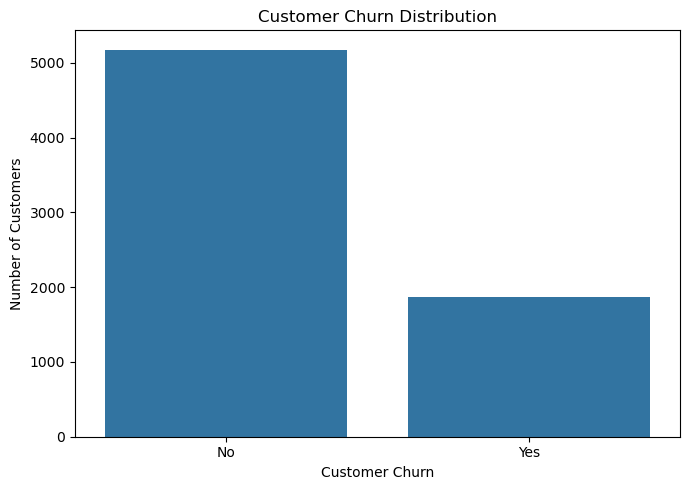

In [121]:

import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create the images folder if it doesn't exist
Path("../images").mkdir(parents=True, exist_ok=True)

# Plot customer churn distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


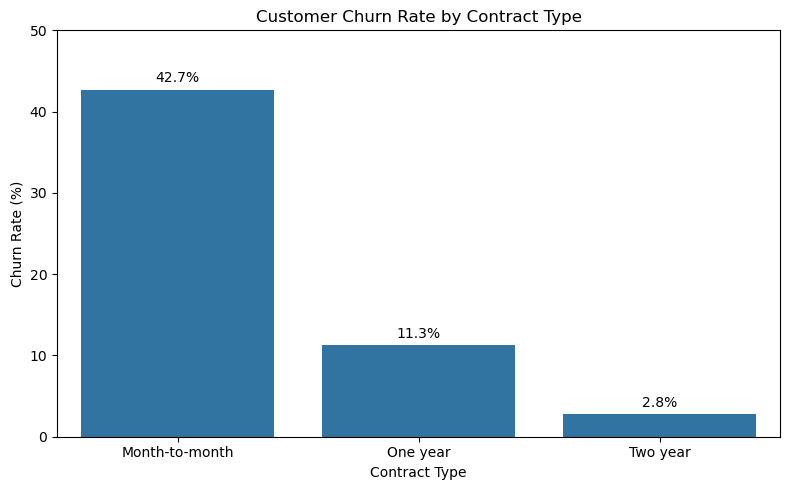

In [122]:

# Calculate churn rate for each contract type
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

# Create the chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

# Show the percentage above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


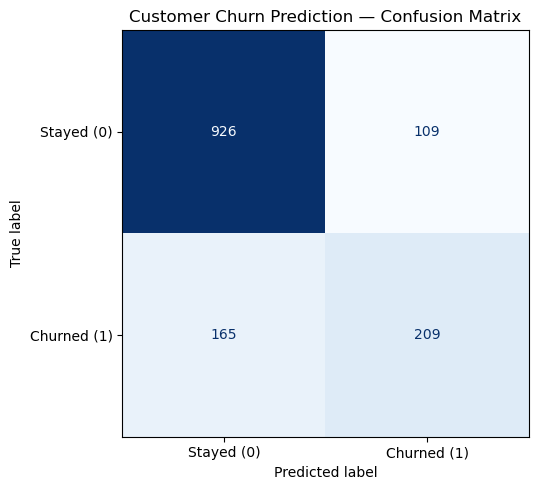

In [125]:
# Create the confusion matrix


from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate the confusion matrix using encoded labels
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

# Create the plot
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed (0)", "Churned (1)"]
)

fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap="Blues", ax=ax, values_format="d", colorbar=False)

plt.title("Customer Churn Prediction — Confusion Matrix")
plt.tight_layout()
plt.show()


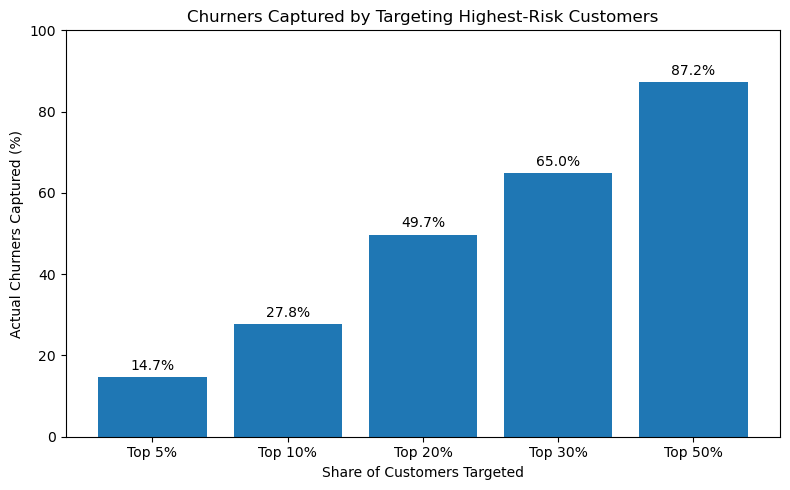

In [127]:
# Customer targeting performance


import numpy as np
import matplotlib.pyplot as plt

# Get predicted churn probabilities for the test set.
# Replace "model" with your fitted final pipeline's variable name if needed.
y_proba = model.predict_proba(X_test)[:, 1]

# Rank customers from highest to lowest churn risk
ranked_indices = np.argsort(y_proba)[::-1]
y_test_array = np.asarray(y_test)
ranked_actual = y_test_array[ranked_indices]

# Calculate the percentage of actual churners captured
target_percentages = [5, 10, 20, 30, 50]
total_churners = np.sum(y_test_array == 1)
capture_rates = []

for percentage in target_percentages:
    n_targeted = max(1, int(len(ranked_actual) * percentage / 100))
    churners_captured = np.sum(ranked_actual[:n_targeted] == 1)
    capture_rates.append(churners_captured / total_churners * 100)

# Plot targeting performance
plt.figure(figsize=(8, 5))
bars = plt.bar(
    [f"Top {p}%" for p in target_percentages],
    capture_rates
)

plt.title("Churners Captured by Targeting Highest-Risk Customers")
plt.xlabel("Share of Customers Targeted")
plt.ylabel("Actual Churners Captured (%)")
plt.ylim(0, 100)

plt.bar_label(bars, fmt="%.1f%%", padding=3)
plt.tight_layout()
